In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

In [2]:
best_model = joblib.load(
    "../data/best_churn_model.pkl"
)

X_train = pd.read_csv(
    "../data/X_train_scaled.csv"
)

print("Best model loaded successfully!")
print("Number of features:", X_train.shape[1])

Best model loaded successfully!
Number of features: 6561


In [3]:
if hasattr(best_model, "feature_importances_"):
    
    importance = best_model.feature_importances_

elif hasattr(best_model, "coef_"):
    
    importance = abs(best_model.coef_[0])

else:
    raise ValueError("This model does not support feature importance.")

print("Feature importance calculated successfully!")

Feature importance calculated successfully!


In [4]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(15))

,Feature,Importance
1,tenure,0.392373
4,numTechTickets,0.323981
11,InternetService_Fiber optic,0.129623
26,Contract_Two year,0.059553
19,TechSupport_No internet service,0.024437
2,MonthlyCharges,0.024343
21,StreamingTV_No internet service,0.020919
10,MultipleLines_Yes,0.008071
18,DeviceProtection_Yes,0.004247
29,PaymentMethod_Electronic check,0.003569


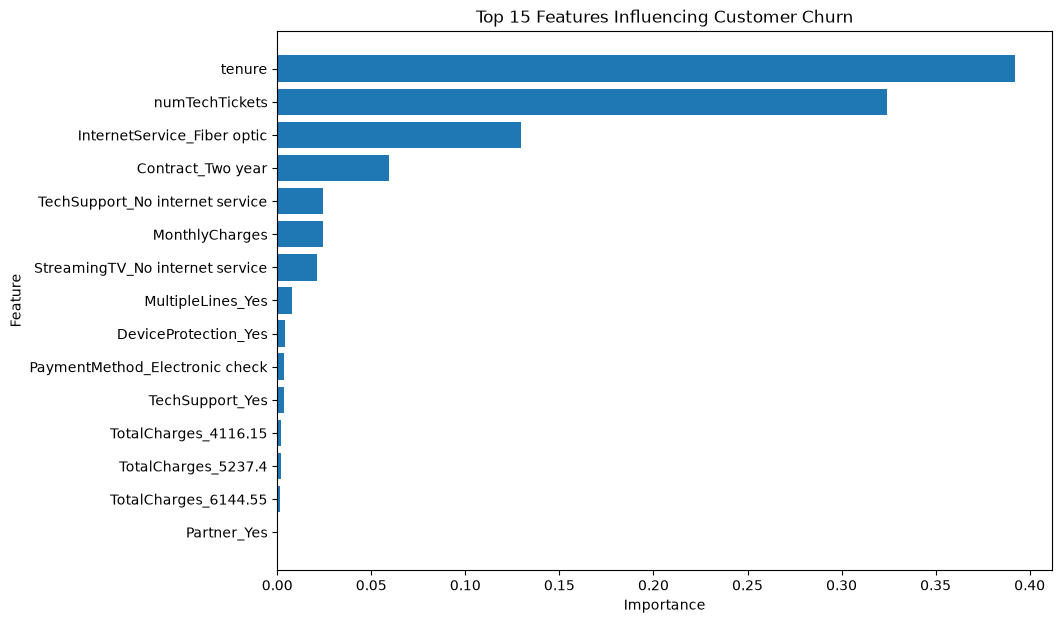

In [5]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Customer Churn")

plt.show()

In [6]:
top_10_features = feature_importance_df.head(10)

display(top_10_features)

,Feature,Importance
1,tenure,0.392373
4,numTechTickets,0.323981
11,InternetService_Fiber optic,0.129623
26,Contract_Two year,0.059553
19,TechSupport_No internet service,0.024437
2,MonthlyCharges,0.024343
21,StreamingTV_No internet service,0.020919
10,MultipleLines_Yes,0.008071
18,DeviceProtection_Yes,0.004247
29,PaymentMethod_Electronic check,0.003569


In [7]:
feature_importance_df.to_csv(
    "../data/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [8]:
most_important_feature = feature_importance_df.iloc[0]

print("Most Important Feature:")
print("Feature:", most_important_feature["Feature"])
print("Importance:", round(most_important_feature["Importance"], 4))

Most Important Feature:
Feature: tenure
Importance: 0.3924
